In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import os
import joblib

from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

caminho_dados = r"../data/processed/dados_sensores_tratados.csv"
dataset = pd.read_csv(caminho_dados)
dataset['timestamp'] = pd.to_datetime(dataset['timestamp'])

features = [
    'temperatura_fuso_c', 'vibracao_triaxial_rms_mms', 'torque_fuso_nm',
    'vazao_refrigerante_lmin', 'corrente_estator_amp', 'pressao_hidraulica_bar',
    'nivel_ruido_db', 'iem',
    'temperatura_fuso_c_rolling_mean_30min', 'temperatura_fuso_c_rolling_std_30min',
    'temperatura_fuso_c_rolling_mean_2h', 'temperatura_fuso_c_rolling_std_2h',
    'vibracao_triaxial_rms_mms_rolling_mean_30min', 'vibracao_triaxial_rms_mms_rolling_std_30min',
    'vibracao_triaxial_rms_mms_rolling_mean_2h', 'vibracao_triaxial_rms_mms_rolling_std_2h',
    'torque_fuso_nm_rolling_mean_30min', 'torque_fuso_nm_rolling_std_30min',
    'torque_fuso_nm_rolling_mean_2h', 'torque_fuso_nm_rolling_std_2h'
]

# Ordenação cronológica estrita
dataset_temporal = dataset.sort_values(by=['id_celula', 'timestamp']).reset_index(drop=True)
X = dataset_temporal[features]
y = dataset_temporal['tipo_falha']

# Divisão temporal 70/30
split_point = int(len(dataset_temporal) * 0.70)
X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

In [2]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Random Forest balanceado
model_rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train_scaled, y_train)

# Gradient Boosting
model_gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
model_gb.fit(X_train_scaled, y_train)

,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

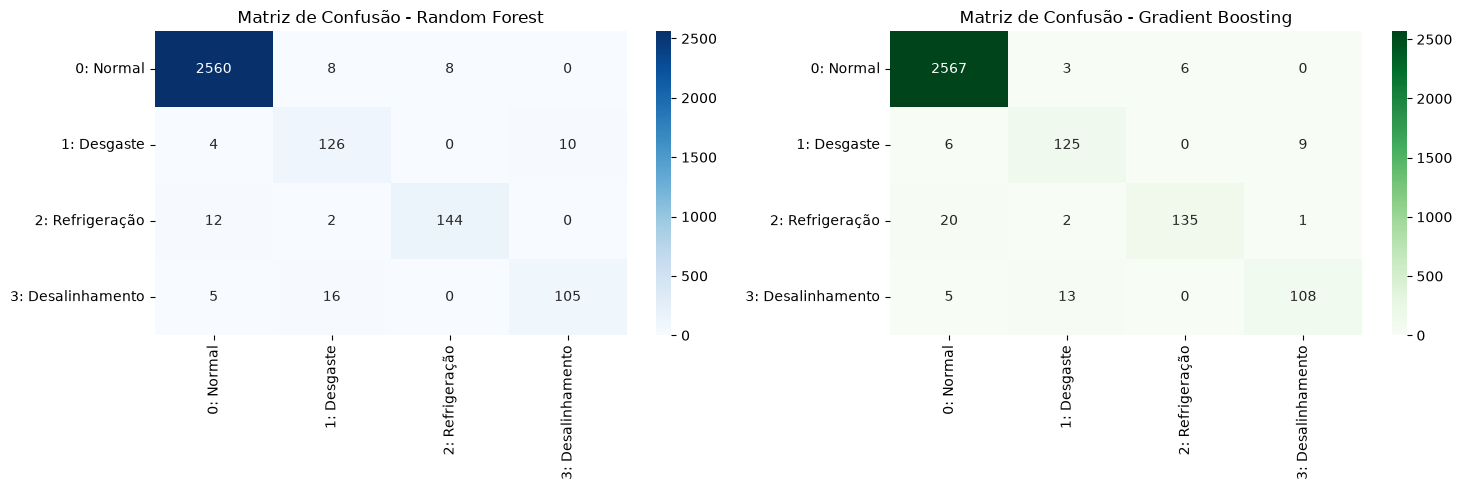

                   precision    recall  f1-score   support

        0: Normal       0.99      0.99      0.99      2576
      1: Desgaste       0.83      0.90      0.86       140
  2: Refrigeração       0.95      0.91      0.93       158
3: Desalinhamento       0.91      0.83      0.87       126

         accuracy                           0.98      3000
        macro avg       0.92      0.91      0.91      3000
     weighted avg       0.98      0.98      0.98      3000



In [3]:
classes_nomes = ['0: Normal', '1: Desgaste', '2: Refrigeração', '3: Desalinhamento']
pred_rf = model_rf.predict(X_test_scaled)
pred_gb = model_gb.predict(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sb.heatmap(confusion_matrix(y_test, pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0],
           xticklabels=classes_nomes, yticklabels=classes_nomes)
axes[0].set_title('Matriz de Confusão - Random Forest')

sb.heatmap(confusion_matrix(y_test, pred_gb), annot=True, fmt='d', cmap='Greens', ax=axes[1],
           xticklabels=classes_nomes, yticklabels=classes_nomes)
axes[1].set_title('Matriz de Confusão - Gradient Boosting')
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred_rf, target_names=classes_nomes, zero_division=0))

In [4]:
def calcular_impacto_oee(pred_classe):
    if pred_classe == 0:     # Operação Normal
        disp, perf, qual = 0.95, 0.93, 0.98
    elif pred_classe == 1:   # Desgaste de Fuso/Ferramenta
        disp, perf, qual = 0.75, 0.85, 0.90
    elif pred_classe == 2:   # Obstrução Térmica / Refrigeração
        disp, perf, qual = 0.80, 0.70, 0.82
    else:                    # 3: Desalinhamento da Matriz / Trinca
        disp, perf, qual = 0.40, 0.60, 0.70
    
    oee = disp * perf * qual
    return disp * 100, perf * 100, qual * 100, oee * 100

oee_resultados = [calcular_impacto_oee(p)[3] for p in pred_rf]
print(f"OEE Médio Projetado no Teste: {np.mean(oee_resultados):.2f}%")
print(f"OEE Mínimo Crítico Registrado: {np.min(oee_resultados):.2f}%")

OEE Médio Projetado no Teste: 80.37%
OEE Mínimo Crítico Registrado: 16.80%


C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_18896\2597370084.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(data=df_importancias, x='Importância', y='Variável / Sensor', palette='crest')


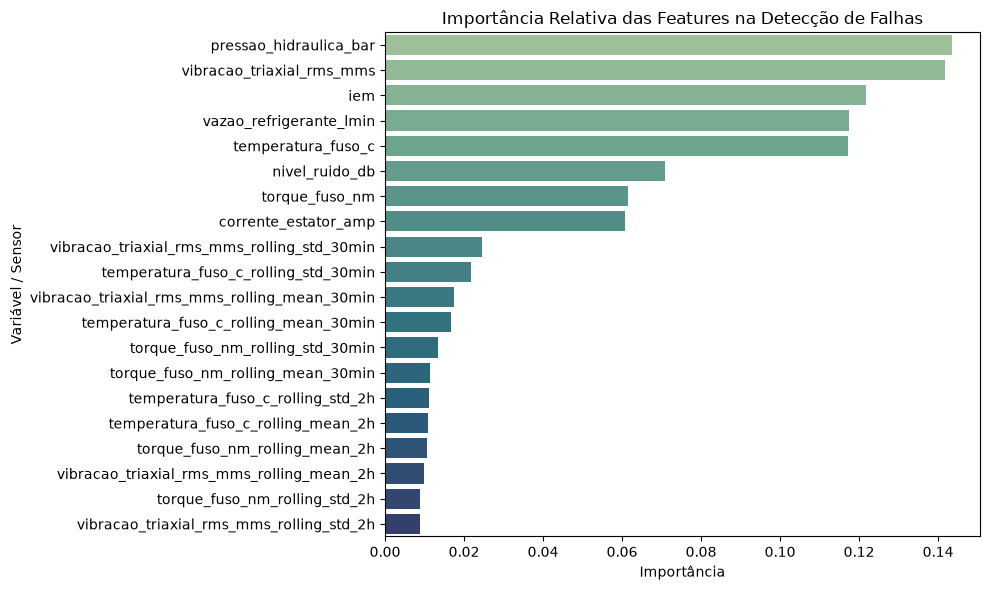

In [5]:
df_importancias = pd.DataFrame({
    'Variável / Sensor': features,
    'Importância': model_rf.feature_importances_
}).sort_values(by='Importância', ascending=False)

plt.figure(figsize=(10, 6))
sb.barplot(data=df_importancias, x='Importância', y='Variável / Sensor', palette='crest')
plt.title('Importância Relativa das Features na Detecção de Falhas')
plt.tight_layout()
plt.show()

In [6]:
pasta_ia = r"../Ficheiros_IA"
os.makedirs(pasta_ia, exist_ok=True)

caminho_modelo = os.path.join(pasta_ia, "modelo_falhas_vulcantech.joblib")
caminho_scaler = os.path.join(pasta_ia, "scaler_vulcantech.joblib")

joblib.dump(model_rf, caminho_modelo)
joblib.dump(scaler, caminho_scaler)

print(f"Modelo campeão salvo em: {caminho_modelo}")
print(f"Scaler salvo em: {caminho_scaler}")

Modelo campeão salvo em: ../Ficheiros_IA\modelo_falhas_vulcantech.joblib
Scaler salvo em: ../Ficheiros_IA\scaler_vulcantech.joblib


In [7]:
# 1. Definição explícita dos 4 novos cenários de teste operacional
novos_cenarios = pd.DataFrame([
    # Cenário 1: Operação Padrão Normal (baixa vibração, temperatura e torque nominais)
    [48.0, 1.8, 110.0, 28.0, 25.0, 160.0, 58.0, 7.07, 47.5, 0.4, 47.0, 0.6, 1.7, 0.1, 1.6, 0.2, 108.0, 2.0, 105.0, 3.0],
    # Cenário 2: Desgaste Severo de Fuso/Ferramenta (torque elevado, vibração alta)
    [72.0, 6.2, 195.0, 22.0, 48.0, 155.0, 79.0, 52.56, 68.0, 2.5, 65.0, 3.0, 5.8, 0.8, 5.2, 1.0, 190.0, 5.0, 185.0, 6.0],
    # Cenário 3: Falha de Refrigeração (temperatura alta, vazão reduzida)
    [84.0, 2.5, 130.0, 10.0, 32.0, 150.0, 62.0, 29.54, 78.0, 4.0, 70.0, 5.5, 2.4, 0.3, 2.3, 0.4, 128.0, 3.0, 125.0, 4.0],
    # Cenário 4: Desalinhamento da Matriz / Trinca (pico acústico e anomalia de pressão)
    [55.0, 8.5, 170.0, 26.0, 39.0, 95.0, 92.0, 53.51, 54.0, 1.0, 53.0, 1.2, 7.8, 1.1, 7.2, 1.4, 165.0, 4.0, 160.0, 5.0]
], columns=features)

# 2. Aplicação do scaler e predição com probabilidades
cenarios_scaled = scaler.transform(novos_cenarios)
predicoes = model_rf.predict(cenarios_scaled)
probabilidades = model_rf.predict_proba(cenarios_scaled)

# 3. Mapeamento de ações industriais prescritivas
mapa_acoes = {
    0: 'MANTER_OPERACAO',
    1: 'REDUZIR_VELOCIDADE_50%',
    2: 'REDUZIR_VELOCIDADE_50%',
    3: 'INTERROMPER_EMERGENCIA'
}

diagnosticos = [classes_nomes[p] for p in predicoes]
acoes = [mapa_acoes[p] for p in predicoes]
confiancas = [f"{np.max(prob)*100:.1f}%" for prob in probabilidades]

# 4. Tabela consolidada com os resultados da simulação
resultado_simulacao = pd.DataFrame({
    'Temperatura (°C)': novos_cenarios['temperatura_fuso_c'],
    'Vibração (mm/s)': novos_cenarios['vibracao_triaxial_rms_mms'],
    'Torque (Nm)': novos_cenarios['torque_fuso_nm'],
    'Vazão (L/min)': novos_cenarios['vazao_refrigerante_lmin'],
    'Diagnóstico Predito': diagnosticos,
    'Confiança': confiancas,
    'Ação Recomendada': acoes
})

print("--- Resultados da Simulação em Chão de Fábrica ---")
display(resultado_simulacao)

--- Resultados da Simulação em Chão de Fábrica ---


,Temperatura (°C),Vibração (mm/s),Torque (Nm),Vazão (L/min),Diagnóstico Predito,Confiança,Ação Recomendada
0,48.0,1.8,110.0,28.0,0: Normal,91.8%,MANTER_OPERACAO
1,72.0,6.2,195.0,22.0,1: Desgaste,67.8%,REDUZIR_VELOCIDADE_50%
2,84.0,2.5,130.0,10.0,2: Refrigeração,93.3%,REDUZIR_VELOCIDADE_50%
3,55.0,8.5,170.0,26.0,3: Desalinhamento,73.3%,INTERROMPER_EMERGENCIA
